# 一、数据操作

In [6]:
#张量表示的是一个数值组成的数组，这个数组可能有多个维度
import torch
from torch.autograd import backward

x= torch.arange(12)
x

tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11])

In [4]:
#张量的形状
x.shape

torch.Size([12])

In [5]:
#张量里面元素的总数
x.numel()

12

In [7]:
#改变一个张量的形状而不改变元素数量和元素值
x = x.reshape(3,4)
x

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11]])

In [8]:
#使用全0，全1，其他常量或者从特定分布中随机采样的数字
torch.zeros((2,3,4))

tensor([[[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]],

        [[0., 0., 0., 0.],
         [0., 0., 0., 0.],
         [0., 0., 0., 0.]]])

In [9]:
torch.ones((2,3,4))

tensor([[[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]],

        [[1., 1., 1., 1.],
         [1., 1., 1., 1.],
         [1., 1., 1., 1.]]])

In [10]:
#通过提供包含数值的python列表（或嵌套列表）来为所需张量中的每个元素赋予确定值
torch.tensor([[2,1,4,3],[1,2,3,4],[4,3,2,1]])

tensor([[2, 1, 4, 3],
        [1, 2, 3, 4],
        [4, 3, 2, 1]])

In [11]:
#常见的标准算术运算符（按元素进行运算）
x = torch.tensor([1.0,2,4,8])
y = torch.tensor([2,2,2,2])
x + y,x - y,x * y,x / y,x**y

(tensor([ 3.,  4.,  6., 10.]),
 tensor([-1.,  0.,  2.,  6.]),
 tensor([ 2.,  4.,  8., 16.]),
 tensor([0.5000, 1.0000, 2.0000, 4.0000]),
 tensor([ 1.,  4., 16., 64.]))

In [17]:
#把多个张量连结在一起
x = torch.arange(24,dtype=torch.float32).reshape((2,3,4))
y = torch.tensor([[[2.0,1,4,3],[1,2,3,4],[4,3,2,1]],
                  [[2.0,1,4,3],[1,2,3,4],[4,3,2,1]]])
torch.cat((x,y),dim=0),torch.cat((x,y),dim=1),torch.cat((x,y),dim=2) #dim：控制连结的维度

(tensor([[[ 0.,  1.,  2.,  3.],
          [ 4.,  5.,  6.,  7.],
          [ 8.,  9., 10., 11.]],
 
         [[12., 13., 14., 15.],
          [16., 17., 18., 19.],
          [20., 21., 22., 23.]],
 
         [[ 2.,  1.,  4.,  3.],
          [ 1.,  2.,  3.,  4.],
          [ 4.,  3.,  2.,  1.]],
 
         [[ 2.,  1.,  4.,  3.],
          [ 1.,  2.,  3.,  4.],
          [ 4.,  3.,  2.,  1.]]]),
 tensor([[[ 0.,  1.,  2.,  3.],
          [ 4.,  5.,  6.,  7.],
          [ 8.,  9., 10., 11.],
          [ 2.,  1.,  4.,  3.],
          [ 1.,  2.,  3.,  4.],
          [ 4.,  3.,  2.,  1.]],
 
         [[12., 13., 14., 15.],
          [16., 17., 18., 19.],
          [20., 21., 22., 23.],
          [ 2.,  1.,  4.,  3.],
          [ 1.,  2.,  3.,  4.],
          [ 4.,  3.,  2.,  1.]]]),
 tensor([[[ 0.,  1.,  2.,  3.,  2.,  1.,  4.,  3.],
          [ 4.,  5.,  6.,  7.,  1.,  2.,  3.,  4.],
          [ 8.,  9., 10., 11.,  4.,  3.,  2.,  1.]],
 
         [[12., 13., 14., 15.,  2.,  1.,  4.,  3.],
   

In [18]:
#通过逻辑运算符构建二元张量
x == y

tensor([[[False,  True, False,  True],
         [False, False, False, False],
         [False, False, False, False]],

        [[False, False, False, False],
         [False, False, False, False],
         [False, False, False, False]]])

In [19]:
#对张量中的所有元素进行求和
x.sum()

tensor(276.)

In [31]:
#广播机制: *要求*两个张量在某个维度上大小相等 OR 其中一个张量在该维度上等于1
a = torch.arange(3).reshape((3,1))
b = torch.arange(2).reshape((1,2))
a,b

(tensor([[0],
         [1],
         [2]]),
 tensor([[0, 1]]))

In [32]:
a + b

tensor([[0, 1],
        [1, 2],
        [2, 3]])

In [47]:
#元素的访问
print(x)
#三维数组
x[:,:,-1] #所有层，所有行的最后一列（层，行，列）
#二维
x[0][-1] ,x[0][:,1:3]

tensor([[[ 0.,  1.,  2.,  3.],
         [ 4.,  5.,  6.,  7.],
         [ 8.,  9., 10., 11.]],

        [[12., 13., 14., 15.],
         [16., 17., 18., 19.],
         [20., 21., 22., 23.]]])


(tensor([ 8.,  9., 10., 11.]),
 tensor([[ 1.,  2.],
         [ 5.,  6.],
         [ 9., 10.]]))

In [49]:
# 通过指定索引来将元素写入矩阵
x[0][1,2] = 9
x[0]

tensor([[ 0.,  1.,  2.,  3.],
        [ 4.,  5.,  9.,  7.],
        [ 8.,  9., 10., 11.]])

In [50]:
# 为多个元素赋值相同的值
x[0][0:2,:] = 12
x[0]

tensor([[12., 12., 12., 12.],
        [12., 12., 12., 12.],
        [ 8.,  9., 10., 11.]])

In [51]:
# 运行一些操作可能会导致为新国分配内存
before = id(y)
y = y + x
id(y) == before

False

In [52]:
# 执行原地操作
z = torch.zeros_like(y)
print('id(z):',id(z))
z[:] = x + y #如果具体到了单个元素索引，不会分配新的内存
print('id(z):',id(z))

id(z): 2236681369648
id(z): 2236681369648


In [56]:
# 如果后续再没有用到y了,为了减少内存开销
before = id(y)
y[:] += x
id(y) == before

True

In [57]:
# 转换为numpy张量
A = x.numpy()
B = torch.tensor(A)
type(A),type(B)

(numpy.ndarray, torch.Tensor)

In [2]:
# 将大小为1的张量转换为python标量
import torch
a = torch.tensor([3.5])
a,a.item(),float(a),int(a)

(tensor([3.5000]), 3.5, 3.5, 3)

## 数据预处理实现

In [4]:
import os
# 创建一个csv文件（逗号分隔值）
os.makedirs(os.path.join('..','data'),exist_ok=True)
data_file = os.path.join('..','data','house_tiny.csv')
with open(data_file,'w') as f:
    f.write('NumRooms,Alley,Price\n') # 列名
    f.write('NA,Pave,127500\n') # 每行表示一个数据样本
    f.write('2.0,NA,106000\n')
    f.write('4.0,NA,178100\n')
    f.write('NA,NA,140000\n')


In [5]:
import pandas as pd

data = pd.read_csv(data_file)
print(data)

   NumRooms Alley   Price
0       NaN  Pave  127500
1       2.0   NaN  106000
2       4.0   NaN  178100
3       NaN   NaN  140000


In [10]:
inputs = (data.iloc[:,0:2])
outputs = data.iloc[:,2]
inputs = inputs.fillna(inputs.mean(numeric_only=True)) #旧版pandas可以直接跳过缺失值，新版必须添加‘numeric_only=True’计算数值列的均值
print(inputs)

   NumRooms Alley
0       3.0  Pave
1       2.0   NaN
2       4.0   NaN
3       3.0   NaN


In [21]:
#对于不是数值类型的列的处理：将‘NA’视作一个类别
inputs = pd.get_dummies(inputs,dummy_na=True,dtype=int) # 得到的是布尔值，需要添加’dtype=int‘得到‘0’和‘1’
print(inputs)

   NumRooms  Alley_Pave  Alley_nan
0       3.0           1          0
1       2.0           0          1
2       4.0           0          1
3       3.0           0          1


In [23]:
# 现在所有数据都是数字类型了，所以他们可以转换为张量
import torch
x,y = torch.tensor(inputs.values,dtype=torch.float32),torch.tensor(outputs.values,dtype=torch.float32)
print(x,y)

tensor([[3., 1., 0.],
        [2., 0., 1.],
        [4., 0., 1.],
        [3., 0., 1.]]) tensor([127500., 106000., 178100., 140000.])


## 线性代数

In [24]:
# 标量由只有一个元素的张量表示
import torch

x = torch.tensor([3.0])
y = torch.tensor([2.0])

x+y,x*y,x/y,x**y

(tensor([5.]), tensor([6.]), tensor([1.5000]), tensor([9.]))

In [32]:
# 向量：标量值组成的列表
x = torch.arange(4)
print(x)
# 通过索引来访问任一元素
print(x[2])
# 长度
print(len(x))
# 形状
print(x.shape)

tensor([0, 1, 2, 3])
tensor(2)
4
torch.Size([4])


In [33]:
# 创建矩阵
A = torch.arange(20).reshape(5,4)
print(A)

tensor([[ 0,  1,  2,  3],
        [ 4,  5,  6,  7],
        [ 8,  9, 10, 11],
        [12, 13, 14, 15],
        [16, 17, 18, 19]])


In [34]:
# 矩阵的转置
A.T

tensor([[ 0,  4,  8, 12, 16],
        [ 1,  5,  9, 13, 17],
        [ 2,  6, 10, 14, 18],
        [ 3,  7, 11, 15, 19]])

In [37]:
# 对称矩阵转置等于其本身
B = torch.tensor([[1,2,3],[2,0,4],[3,4,5]])
print(B)
B == B.T

tensor([[1, 2, 3],
        [2, 0, 4],
        [3, 4, 5]])


tensor([[True, True, True],
        [True, True, True],
        [True, True, True]])

In [40]:
# 构建具有更多轴的数据结构
# 行是最后一维，列是倒数第二维，层是第一维
X = torch.arange(24).reshape(2,3,4) # .reshape(层，行，列）
print(X)

tensor([[[ 0,  1,  2,  3],
         [ 4,  5,  6,  7],
         [ 8,  9, 10, 11]],

        [[12, 13, 14, 15],
         [16, 17, 18, 19],
         [20, 21, 22, 23]]])


In [41]:
# 具有相同形状的两个张量，按元素二元运算的结果是相同形状的张量
A = torch.arange(20,dtype=torch.float32).reshape(5,4)
B = A.clone() # 把A的一个副本给B，为B重新分配地址
A, A+B

(tensor([[ 0.,  1.,  2.,  3.],
         [ 4.,  5.,  6.,  7.],
         [ 8.,  9., 10., 11.],
         [12., 13., 14., 15.],
         [16., 17., 18., 19.]]),
 tensor([[ 0.,  2.,  4.,  6.],
         [ 8., 10., 12., 14.],
         [16., 18., 20., 22.],
         [24., 26., 28., 30.],
         [32., 34., 36., 38.]]))

In [42]:
# 两个矩阵按元素的乘法被称为‘哈达玛积’，数学符号为圈里面有个点
A * B

tensor([[  0.,   1.,   4.,   9.],
        [ 16.,  25.,  36.,  49.],
        [ 64.,  81., 100., 121.],
        [144., 169., 196., 225.],
        [256., 289., 324., 361.]])

In [43]:
# 标量乘矩阵
a = 2
X = torch.arange(24).reshape(2,3,4)
a + X,(a * X).shape

(tensor([[[ 2,  3,  4,  5],
          [ 6,  7,  8,  9],
          [10, 11, 12, 13]],
 
         [[14, 15, 16, 17],
          [18, 19, 20, 21],
          [22, 23, 24, 25]]]),
 torch.Size([2, 3, 4]))

In [86]:
# 对张量求和
x = torch.arange(4.0,dtype=torch.float32)
x,x.sum()

(tensor([0., 1., 2., 3.]), tensor(6.))

In [57]:
A = torch.arange(20.0*2).reshape(2,5,4)
A.shape,A.sum()

(torch.Size([2, 5, 4]), tensor(780.))

In [50]:
# 指定张量的维度求和
A_sum_axis0 = A.sum(axis=0)
A_sum_axis0.shape,A_sum_axis0
# 按照零维就是‘层’来求和，就是第一层的行和列加第二层的行和列，数据结构变成平面，只有行和列的

(torch.Size([5, 4]),
 tensor([[20, 22, 24, 26],
         [28, 30, 32, 34],
         [36, 38, 40, 42],
         [44, 46, 48, 50],
         [52, 54, 56, 58]]))

In [51]:
A_sum_axis1 = A.sum(axis=1)
A_sum_axis1.shape,A_sum_axis1
# 按照1维就是‘行’来求和，数据结构变成平面，剩下层和列的数据

(torch.Size([2, 4]),
 tensor([[ 40,  45,  50,  55],
         [140, 145, 150, 155]]))

In [52]:
A_sum_axis2 = A.sum(axis=2)
A_sum_axis2.shape, A_sum_axis2
# 按照2维就是‘列’来求和，数据结构变成平面，剩下层和行的数据

(torch.Size([2, 5]),
 tensor([[  6,  22,  38,  54,  70],
         [ 86, 102, 118, 134, 150]]))

In [55]:
# 也可以用两个维度求和
print(A.sum(axis=[0,1]))
A.sum(axis=[0,1]).shape
# 因为使用‘层’和‘行’来求和，所以shape应该是剩下的那个‘列’的样子

tensor([180, 190, 200, 210])


torch.Size([4])

In [59]:
# 求均值
A.mean(),A.sum()/A.numel()

(tensor(19.5000), tensor(19.5000))

In [72]:
# 按照维度求均值
A = torch.arange(20.0).reshape(5,4) # 求均值不能对整数求，改成浮点数‘202.0’
A.mean(axis=0),A.sum(axis=0)/A.shape[0]

(tensor([ 8.,  9., 10., 11.]), tensor([ 8.,  9., 10., 11.]))

In [74]:
# 每个维度的数量
A.shape[0],A.shape[1],A.shape

(5, 4, torch.Size([5, 4]))

In [77]:
# 求和时不改变维度
sum_A = A.sum(axis=1,keepdim=True)
sum_A
# 不改变维度的好处是：求完之后保留下来的那个维度大小会变成1，可以通过广播机制让A可以除以sum_A

tensor([[ 6],
        [22],
        [38],
        [54],
        [70]])

In [78]:
# 通过广播机制将A除以sum_A
A / sum_A

tensor([[0.0000, 0.1667, 0.3333, 0.5000],
        [0.1818, 0.2273, 0.2727, 0.3182],
        [0.2105, 0.2368, 0.2632, 0.2895],
        [0.2222, 0.2407, 0.2593, 0.2778],
        [0.2286, 0.2429, 0.2571, 0.2714]])

In [80]:
# 某个轴计算A元素的累计总和
A,A.cumsum(axis=0)

(tensor([[ 0,  1,  2,  3],
         [ 4,  5,  6,  7],
         [ 8,  9, 10, 11],
         [12, 13, 14, 15],
         [16, 17, 18, 19]]),
 tensor([[ 0,  1,  2,  3],
         [ 4,  6,  8, 10],
         [12, 15, 18, 21],
         [24, 28, 32, 36],
         [40, 45, 50, 55]]))

In [82]:
# 点积:按元素乘然后求和，结果是一个标量
y = torch.ones(4,dtype=torch.float32)
x,y,torch.dot(x,y)

(tensor([0., 1., 2., 3.]), tensor([1., 1., 1., 1.]), tensor(6.))

In [83]:
# 等价于按元素乘法，然后求和
torch.sum(x*y)

tensor(6.)

In [91]:
# 矩阵乘向量
x = torch.arange(4.0,dtype=torch.float32) #x.shape=n
A = torch.arange(20.0).reshape(5,4) #A.shape=m*n
A.shape,x.shape,torch.mv(A,x) #result.shape=m
# result[i]是a[i]和x的转置的点积

(torch.Size([5, 4]), torch.Size([4]), tensor([ 14.,  38.,  62.,  86., 110.]))

In [93]:
# 两个矩阵相乘
B = torch.ones(4,3)
torch.mm(A,B)

tensor([[ 6.,  6.,  6.],
        [22., 22., 22.],
        [38., 38., 38.],
        [54., 54., 54.],
        [70., 70., 70.]])

In [95]:
# 向量范数
# L2范数：每个元素平方相加再开根号
u = torch.tensor([3.0,-4.0])
torch.norm(u)

tensor(5.)

In [96]:
# L1范数：向量元素的绝对值之和
torch.abs(u).sum()

tensor(7.)

In [97]:
# 矩阵范数
# Frobenius norm：等价于L2范数
torch.norm(torch.ones((4,9)))

tensor(6.)

## 自动求导

In [1]:
import torch

x = torch.arange(4.0)
x

tensor([0., 1., 2., 3.])

In [2]:
# 在计算梯度之前，我们需要一个地方来储存梯度
x.requires_grad_(True)  # 等价于 x = torch.arange(4.0,requires_grad=True
x.grad # 默认值是None

In [9]:
y = 2 * torch.dot(x,x)
y

tensor(28., grad_fn=<MulBackward0>)

In [10]:
# 通过反向传播函数来自动计算y关于x每个分量的梯度
y.backward() # 求导
x.grad

tensor([ 0.,  8., 16., 24.])

In [5]:
x.grad == 4 * x

tensor([True, True, True, True])

In [12]:
# 在默认情况下，pytorch会累积梯度，在下一个计算之前，我们要清除之前的值
x.grad.zero_() #下划线'_'表示重写内容，zero_ 表示把零重写进x.grad
y = x.sum()
y.backward()
x.grad

tensor([1., 1., 1., 1.])

In [13]:
# 对非标量调用'backward'需要传入一个gradient参数
x.grad.zero_()
y = x * x
# 等价于y.backward(torch.ones(len(x)))
y.sum().backward()
x.grad

tensor([0., 2., 4., 6.])

In [15]:
# 将某些计算移动到记录的计算图之外
x.grad.zero_()
y = x * x
u = y.detach() # 把y当作一个常数
z = u * x

z.sum().backward()
x.grad ==u

tensor([True, True, True, True])

In [16]:
x.grad.zero_()
y.sum().backward()
x.grad == 2 * x

tensor([True, True, True, True])

In [18]:
# 控制流
def f(a):
    b = a *  2
    while b.norm() < 1000:
        b = b * 2
    if b.sum() > 0:
        c = b
    else:
        c = 100 * b
    return c

a = torch.randn(size=(),requires_grad=True)
d = f(a)
d.backward()
a.grad == d/a


tensor(True)

## 线性回归的从零开始实现

In [42]:
%matplotlib inline
import random
import torch
from  matplotlib import pyplot as plt #导入画图库

In [43]:
# 根据带有噪声的线性模型构造一个人造数据集
# y = Xw + b + 噪声
# w = 【2，-3.4】T ； b = 4.2
def synthetic_data(w,b,num_examples):
    X = torch.randn((num_examples,w.shape[0])) # torch.normal(a,b,size)完全等价于torch.randn(size)【生成均值为0，标准差为1的随机数】 * b(标准差) + a(均值)
    y = torch.matmul(X,w) + b
    y += torch.randn(y.shape) * 0.01
    return X,y.reshape(-1,1)

true_w = torch.tensor([2,-3.4])
true_b = 4.2
features,labels = synthetic_data(true_w,true_b,1000)


In [44]:
print('features',features[0])
print('labels',labels[0])

features tensor([-0.5637,  0.7773])
labels tensor([0.4335])


torch.Size([1, 2])
torch.Size([1000, 1])


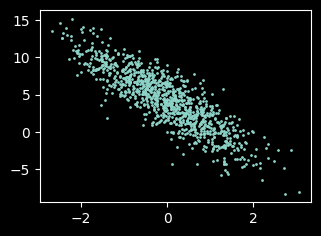

In [45]:
print(features[:1].shape)
print(labels.shape)
# 可视化
#设置图片大小
plt.figure(figsize=(3.5,2.5))
#画散点图
##Tensor不能直接画图，必须要转成numpy数组：.detach()【先剥离出来】.numpy()【再转换成numpy】
## s=1是点的大小
plt.scatter(features[:,1].detach().numpy(),
            labels.detach().numpy(),
            s=1)
#显示图片
plt.show()

In [46]:
# 小批量数据迭代器
# 定义一个生成器函数
def data_iter(batch_size, features, labels):
# 初始化与打乱数据
    num_examples = len(features)
    indices = list(range(num_examples))
    # 随机读取样本
    random.shuffle(indices)
# 按批次循环与切片
    for i in range(0, num_examples, batch_size):
        batch_indices = torch.tensor(
            indices[i:min(i + batch_size, num_examples)] # 使用min是防止越界，result是python列表
        )# 用torch.tensor转换成张量计算
# 生成器返回数据
        yield features[batch_indices], labels[batch_indices]

### 测试代码
batch_size = 10

for X,y in data_iter(batch_size, features, labels):
    print(X,'\n',y)
    break

tensor([[-0.7435, -1.8174],
        [ 0.5354, -1.3330],
        [-0.1555, -1.4966],
        [-0.6106,  1.0933],
        [-0.4767, -0.2429],
        [ 0.3414,  0.2032],
        [ 1.1875, -0.6991],
        [ 1.7179, -0.8017],
        [ 1.0820, -0.7027],
        [ 0.0296, -2.4423]]) 
 tensor([[ 8.8909],
        [ 9.7872],
        [ 8.9761],
        [-0.7310],
        [ 4.0803],
        [ 4.1904],
        [ 8.9340],
        [10.3623],
        [ 8.7575],
        [12.5575]])


In [47]:
# 定义 初始化模型参数
w = torch.normal(0,0.01,size=(2,1),requires_grad=True)
b = torch.zeros(1,requires_grad=True)

In [48]:
# 定义模型
def linreg(X,w,b):
    """线性回归模型"""
    return torch.matmul(X,w) + b

In [49]:
# 定义损失函数
# y_hat 是预测值，y是真实值
def squared_loss(y_hat,y):
    """均方损失"""
    return (y_hat - y.reshape(y_hat.shape))**2/2

In [50]:
# 定义优化算法
# sgd(给定参数【list】，学习率，batch_size)
def sgd(params,lr,batch_size):
    """小批量随机梯度下降"""
    with torch.no_grad():
        for param in params:
            param -= lr * param.grad / batch_size
            param.grad.zero_()

In [51]:
### 训练过程
lr = 0.03 #学习率【不能太大也不能太小】
num_epochs = 3 #把整个模型扫三遍
net = linreg
loss = squared_loss

for epoch in range(num_epochs):
    for X, y in data_iter(batch_size, features, labels):
        l = loss(net(X,w,b),y)
        l.sum().backward()
        # 使用参数的梯度更新参数
        sgd([w,b],lr,batch_size)
    # 检测一下当前的进度
    with torch.no_grad():
        train_l = loss(net(features,w,b),labels)
        print(f'epoch{epoch + 1},loss{float(train_l.mean()):f}')

epoch1,loss0.032326
epoch2,loss0.000106
epoch3,loss0.000049


In [52]:
# 比较真实参数和通过训练学到的参数来评估训练的成功程度
print(f'w的估计误差:{true_w - w.reshape(true_w.shape)}')
print(f'b的估计误差:{true_b - b}')

w的估计误差:tensor([-0.0001,  0.0003], grad_fn=<SubBackward0>)
b的估计误差:tensor([0.0011], grad_fn=<RsubBackward1>)


## 线性回归的简洁实现

In [65]:
import numpy as np
import torch
from torch.utils import data

true_w = torch.tensor([2,-3.4])
true_b = 4.2
features =  torch.normal(0,1,(1000,2)) # 生成1000个样本，每个样本2个特征
labels = (features @ true_w + true_b +torch.normal(0,0.01,(1000,))).reshape(-1,1) # 计算y，加噪音，转换成向量 ##-1:占位，该维度让torch自己计算
## @ 表示矩阵乘法， * 表示逐个元素相乘

In [67]:
def load_array(data_array,batch_size,is_train=True):
    """构造一个pytorch数据迭代器"""
    dataset = data.TensorDataset(*data_array) ## data.TensorDataset():打包特征张量和标签张量【要求第一维必须一样，即样本总数】
    return data.DataLoader(dataset,batch_size,shuffle=is_train)

batch_size = 10
data_iter = load_array((features,labels),batch_size)

next(iter(data_iter))

[tensor([[-1.2262, -1.3926],
         [-0.0430, -0.1311],
         [-0.0042, -0.5200],
         [ 0.8888, -1.0433],
         [ 0.7304,  0.3706],
         [-0.1563,  0.1944],
         [-0.0959, -0.0394],
         [ 0.0347, -1.3860],
         [-2.1602,  0.7208],
         [ 0.3499,  1.5937]]),
 tensor([[ 6.4951],
         [ 4.5542],
         [ 5.9883],
         [ 9.5313],
         [ 4.4127],
         [ 3.2329],
         [ 4.1556],
         [ 8.9905],
         [-2.5589],
         [-0.5051]])]

In [69]:
## 使用框架的预定义好的层
from torch import nn

net = nn.Sequential(nn.Linear(2,1)) #nn.Linear(输入维度,输出维度)

In [56]:
## 初始化模型参数
net[0].weight.data.normal_(0,0.1) # 通过下标访问到这个线性回归方程；通过.weight访问到w；通过.data访问到w的真实数据；.normal_(0,0.1):使用正态分布来替换掉data的值
net[0].bias.data.fill_(0) # bias:偏差，真实值和预测值的差

tensor([0.])

In [57]:
# 计算均方误差 # 也称平方范数
loss = nn.MSELoss()

In [58]:
# 实例化sgd实例
trainer = torch.optim.SGD(net.parameters(),lr=0.03) #net.parameters():拿出所有的参数【w和b】

In [64]:
## 训练代码
num_epochs = 3

for epoch in range(num_epochs):
    for X, y in data_iter:
        l = loss(net(X),y) # 因为net里已经有w和b了，所以我们不需要再输入w和b了
        trainer.zero_grad()
        l.backward()
        trainer.step()
    l = loss(net(features),labels)
    print(f'epoch{epoch + 1},loss{l:f}')

epoch1,loss0.000107
epoch2,loss0.000106
epoch3,loss0.000106
